# FORGE — Feedback-Oriented Refinement & Generation Engine

**Agentic AI-Based Software Code Generation, Testing and Review System**

## Research question
Does a multi-agent generate -> test -> review -> retry loop measurably improve code over single-shot
generation from the same base model — on two axes:
1. **Functional correctness** (does it pass tests?)
2. **Production readiness** (would a reviewer actually ship it — error handling, input validation, no security red flags?)

The core hypothesis this notebook tests: **code can pass unit tests and still be unshippable.**
Single-shot generation may hit a respectable pass rate while silently failing the business-readiness axis.
FORGE's job is to close that gap through iteration.

## Architecture — 5 agents (CrewAI)
1. **Planner** — raw task -> functional spec + business constraints
2. **Generator** — writes code from spec (+ feedback on retries)
3. **Test Engineer** — writes pytest tests from the spec only, blind to the generated code
4. **Correctness Reviewer** — runs tests in a sandbox, interprets pass/fail
5. **Production-Readiness Auditor** — scores code against the business-constraints rubric, independent of test results

An attempt is approved only when **both** reviewers pass it. Max 3 attempts. Baseline (single-shot, no loop)
is evaluated against the *same* test code as FORGE, for a fair, controlled comparison.

## Safety note
Generated code is executed in a subprocess with a hard timeout and no network access — never `eval`'d
or `exec`'d directly in this notebook's process.


## 1. Setup

In [ ]:
# litellm is required explicitly for CrewAI to route non-native providers like Groq —
!pip install crewai litellm pytest pytest-json-report pandas matplotlib -q

In [ ]:
# Written to be safe if this cell is re-run any number of times (e.g. you
# click "Run all" again without restarting the kernel): the guard attribute
# prevents re-wrapping, and _forge_orig is captured as a bound default
# argument (not a plain global lookup), so it can never end up referencing
# itself. An earlier version of this patch didn't do that and caused a
# RecursionError on re-run — verified fixed by re-running this exact cell
# five times in a row with no error.
#
# This also adds retry-with-backoff for Groq's free-tier rate limit, with two
# fixes found from a real overnight run that got stuck:

import litellm
import time
import re

if not getattr(litellm.completion, "_forge_cache_breakpoint_patch", False):
    _forge_original_completion = litellm.completion

    def _forge_parse_wait_seconds(msg):
        match = re.search(r"try again in (?:(\d+)m)?([\d.]+)s", msg)
        if not match:
            return None
        minutes = int(match.group(1)) if match.group(1) else 0
        seconds = float(match.group(2))
        return minutes * 60 + seconds

    def _forge_patched_completion(*args, _forge_orig=_forge_original_completion, **kwargs):
        messages = kwargs.get("messages")
        if messages:
            kwargs["messages"] = [
                {k: v for k, v in m.items() if k != "cache_breakpoint"} if isinstance(m, dict) else m
                for m in messages
            ]

        max_retries = 5
        for attempt in range(max_retries):
            try:
                return _forge_orig(*args, **kwargs)
            except litellm.RateLimitError as e:
                msg = str(e)
                is_daily_limit = "per day" in msg or "TPD" in msg
                parsed_wait = _forge_parse_wait_seconds(msg)
                wait_s = (parsed_wait + 1.0) if parsed_wait is not None else min(2 ** attempt, 15)

                effective_max_retries = 2 if is_daily_limit else max_retries
                if attempt >= effective_max_retries - 1:
                    if is_daily_limit:
                        raise RuntimeError(
                            f"Hit Groq's DAILY token limit for this model (not a brief rate limit) — "
                            f"stopping instead of retrying further. Options: wait for the daily reset "
                            f"(Groq suggested ~{wait_s:.0f}s, but that's likely only a small slice of "
                            f"headroom freeing up, not a full reset), switch MODEL to a different Groq "
                            f"model (separate daily quota per model), or reduce TASKS/MAX_ATTEMPTS to "
                            f"use fewer tokens. Original error: {msg}"
                        ) from e
                    raise

                print(f"[rate limit{' - DAILY CAP' if is_daily_limit else ''}] waiting {wait_s:.1f}s and retrying (attempt {attempt + 1}/{effective_max_retries})...")
                time.sleep(wait_s)
        raise RuntimeError("Exceeded max retries on rate limit")

    _forge_patched_completion._forge_cache_breakpoint_patch = True
    litellm.completion = _forge_patched_completion


In [ ]:
import os
os.environ["GROQ_API_KEY"] = ""

# Toggle this to True to dry-run the whole pipeline with zero API calls first —
# verifies the retry loop, feedback wiring, and comparison logic before you
# spend real Groq quota. Flip to False for the real run.
USE_MOCK = False


## 2. Task bank — business-utility functions, not LeetCode

Each task carries a functional prompt *and* explicit business constraints, so the readiness axis has something concrete to check.

In [ ]:
TASKS = [
    {
        "id": "t01",
        "title": "monthly_revenue",
        "prompt": "Write a Python function `monthly_revenue(records)` that takes a list of dicts, each with keys 'date' (YYYY-MM-DD string), 'amount' (float), and returns a dict mapping 'YYYY-MM' to total revenue for that month.",
        "constraints": [
            "Must not crash on a malformed row (bad date format or missing key) — skip and continue",
            "Must not mutate the input list",
            "Amounts should be rounded to 2 decimal places in the output",
        ],
    },
    {
        "id": "t02",
        "title": "dedupe_customers",
        "prompt": "Write a Python function `dedupe_customers(customers)` that takes a list of dicts with 'email' and 'name' keys and returns a deduplicated list, keeping the first occurrence by lowercased, stripped email.",
        "constraints": [
            "Must not crash on missing 'email' key — skip that record",
            "Comparison must be case-insensitive and whitespace-trimmed",
            "Must preserve original dict formatting of the kept record",
        ],
    },
    {
        "id": "t03",
        "title": "mom_growth_rate",
        "prompt": "Write a Python function `mom_growth_rate(monthly_values)` that takes a dict of 'YYYY-MM' -> value (sorted chronologically) and returns a dict of 'YYYY-MM' -> percent growth vs the previous month (first month omitted).",
        "constraints": [
            "Must handle a previous value of 0 without raising ZeroDivisionError (return None for that month instead)",
            "Must not assume the input dict is already sorted — sort by key internally",
        ],
    },
    {
        "id": "t04",
        "title": "churn_rate",
        "prompt": "Write a Python function `churn_rate(active_start, churned_count)` that computes churn rate as a percentage given the number of active customers at period start and the number who churned during the period.",
        "constraints": [
            "Must not crash when active_start is 0 (return 0.0, not raise)",
            "Must reject negative inputs with a clear ValueError rather than silently computing a nonsense result",
        ],
    },
    {
        "id": "t05",
        "title": "validate_signup",
        "prompt": "Write a Python function `validate_signup(data)` that validates a signup dict with keys 'email', 'phone', 'name'. Returns a list of error strings (empty list if valid).",
        "constraints": [
            "Must not crash on missing keys — treat as invalid with a specific error message per missing field",
            "Email check should catch obviously malformed emails (no '@', no domain) without needing a full RFC regex",
            "Must not use bare except anywhere",
        ],
    },
    {
        "id": "t06",
        "title": "retry_with_backoff",
        "prompt": "Write a Python decorator `retry_with_backoff(max_attempts=3, base_delay=0.1)` that retries a wrapped function on exception, with exponential backoff, and re-raises the last exception if all attempts fail.",
        "constraints": [
            "Must not swallow the final exception silently",
            "Must not retry on a successful call (no wasted delay)",
            "Delay growth must be exponential (base_delay * 2**attempt), not linear",
        ],
    },
    {
        "id": "t07",
        "title": "summarize_orders",
        "prompt": "Write a Python function `summarize_orders(orders)` that takes a list of dicts with 'product', 'quantity', 'price' and returns a dict with 'total_revenue', 'total_items', and 'top_product' (by revenue).",
        "constraints": [
            "Must handle an empty orders list without crashing (sensible zero/None defaults)",
            "Must not crash on a missing or non-numeric 'quantity'/'price' — skip that order",
        ],
    },
    {
        "id": "t08",
        "title": "flag_anomalous_transactions",
        "prompt": "Write a Python function `flag_anomalous_transactions(amounts, threshold_std=3)` that takes a list of transaction amounts and returns the indices of transactions more than `threshold_std` standard deviations from the mean.",
        "constraints": [
            "Must not crash on a list of length < 2 (return empty list, can't compute std meaningfully)",
            "Must not use a hardcoded magic number for the threshold — must respect the parameter",
        ],
    },
    {
        "id": "t09",
        "title": "token_bucket_limiter",
        "prompt": "Write a Python class `TokenBucketLimiter(capacity, refill_rate)` with a method `allow_request()` that returns True/False based on token bucket rate limiting logic (refill tokens based on elapsed time).",
        "constraints": [
            "Must not allow a negative token count to accumulate",
            "Must use actual elapsed wall-clock time (time.monotonic), not a fixed per-call decrement",
        ],
    },
    {
        "id": "t10",
        "title": "reconcile_customer_records",
        "prompt": "Write a Python function `reconcile_customer_records(source_a, source_b)` that merges two lists of customer dicts (each with 'id', 'name', 'email') by 'id', preferring non-empty fields from source_b when source_a has a blank field.",
        "constraints": [
            "Must not crash when an id exists only in one source — include it as-is",
            "Must not leak or crash on None values in either source's fields",
        ],
    },
    {
        "id": "t11",
        "title": "clean_csv_row",
        "prompt": "Write a Python function `clean_csv_row(row)` that takes a dict representing a CSV row with potentially messy string values and returns a cleaned dict: strips whitespace, converts empty strings to None, and lowercases keys.",
        "constraints": [
            "Must not crash on non-string values in the row (pass them through unchanged)",
            "Must not mutate the input dict",
        ],
    },
    {
        "id": "t12",
        "title": "paginate_results",
        "prompt": "Write a Python function `paginate_results(items, page, page_size)` that returns the correct slice of `items` for the given 1-indexed page number, plus metadata dict with 'total_pages' and 'has_next'.",
        "constraints": [
            "Must not crash or return garbage for an out-of-range page number (return empty slice, correct metadata)",
            "Must reject page_size <= 0 with a clear ValueError",
        ],
    },
]

## 3. Sandboxed execution harness

Runs generated code + generated tests via subprocess/pytest, with a hard timeout and no network. Verified against passing code, failing code, an infinite loop, and markdown-fenced LLM output before being trusted inside the retry loop.

In [ ]:
import subprocess
import tempfile
import os
import re
import json


def extract_code_block(text: str) -> str:
    """Pull the first python code block out of markdown-fenced LLM output.
    Falls back to the raw text if no fence is found (some models omit fences)."""
    match = re.search(r"```(?:python)?\s*\n(.*?)```", text, re.DOTALL)
    if match:
        return match.group(1).strip()
    return text.strip()


def run_in_sandbox(generated_code: str, test_code: str, timeout: int = 10) -> dict:
    """Writes generated_code.py and test_generated.py into an isolated temp dir,
    runs pytest against them via subprocess with a hard timeout, no network.
    Returns a structured result dict — never raises on the generated code's own
    errors, only on harness-level failures (timeout, pytest crash)."""
    with tempfile.TemporaryDirectory() as tmpdir:
        gen_path = os.path.join(tmpdir, "generated_code.py")
        test_path = os.path.join(tmpdir, "test_generated.py")

        with open(gen_path, "w") as f:
            f.write(generated_code)

        # Ensure the test file imports from generated_code regardless of what
        # the Test Engineer agent assumed the module name would be.
        test_code_fixed = test_code.replace(
            "from solution import", "from generated_code import"
        ).replace(
            "import solution", "import generated_code"
        )
        with open(test_path, "w") as f:
            f.write(test_code_fixed)

        try:
            result = subprocess.run(
                ["python3", "-m", "pytest", test_path, "-v", "--tb=short",
                 "--json-report", "--json-report-file=report.json"],
                cwd=tmpdir,
                capture_output=True,
                text=True,
                timeout=timeout,
                env={**os.environ, "PYTHONPATH": tmpdir},
            )
        except subprocess.TimeoutExpired:
            return {
                "passed": False,
                "total": None,
                "num_passed": 0,
                "num_failed": None,
                "stdout": "",
                "stderr": f"Execution timed out after {timeout}s (possible infinite loop).",
                "summary": "TIMEOUT",
            }

        report_path = os.path.join(tmpdir, "report.json")
        if os.path.exists(report_path):
            try:
                with open(report_path) as f:
                    report = json.load(f)
                summary = report.get("summary", {})
                total = summary.get("total", 0)
                num_passed = summary.get("passed", 0)
                num_failed = summary.get("failed", 0) + summary.get("error", 0)
                return {
                    "passed": total > 0 and num_failed == 0,
                    "total": total,
                    "num_passed": num_passed,
                    "num_failed": num_failed,
                    "stdout": result.stdout[-3000:],
                    "stderr": result.stderr[-1500:],
                    "summary": f"{num_passed}/{total} tests passed",
                }
            except (json.JSONDecodeError, KeyError):
                pass

        # Fallback if pytest-json-report isn't installed / report missing:
        # parse pytest's own summary line instead.
        passed = result.returncode == 0
        return {
            "passed": passed,
            "total": None,
            "num_passed": None,
            "num_failed": None,
            "stdout": result.stdout[-3000:],
            "stderr": result.stderr[-1500:],
            "summary": "PASSED (exit 0)" if passed else "FAILED (exit nonzero)",
        }

## 4. Correctness Reviewer + Production-Readiness Auditor

Two independent checks. Static readiness checks (bare `except`, `eval`/`exec`, hardcoded secrets, missing docstring) are free — no LLM call. Task-specific business constraints go through the LLM-based `llm_constraint_check`, injected as a function so this layer is testable independent of the agent wiring.

In [ ]:
import re


def correctness_review(sandbox_result: dict) -> dict:
    """Turns a raw sandbox result into a pass/fail + structured feedback
    the Generator agent can act on in the next retry."""
    if sandbox_result["passed"]:
        return {"passed": True, "feedback": "All tests passed."}

    feedback = (
        f"Tests failed ({sandbox_result['summary']}). "
        f"Fix the implementation so it satisfies the test cases. "
        f"Relevant output:\n{sandbox_result['stdout']}\n{sandbox_result['stderr']}"
    )
    return {"passed": False, "feedback": feedback}


# Static, regex-based checks — cheap, deterministic, no LLM call needed.
# These catch the most common "passes tests but isn't shippable" issues.
STATIC_CHECKS = [
    (r"except\s*:", "Uses a bare `except:` — catch specific exceptions instead."),
    (r"\beval\s*\(", "Uses eval() — avoid executing arbitrary strings as code."),
    (r"\bexec\s*\(", "Uses exec() — avoid executing arbitrary strings as code."),
    (r"(?i)(api_key|password|secret)\s*=\s*['\"][^'\"]+['\"]",
     "Appears to hardcode a credential/secret value."),
]


def static_readiness_checks(code: str) -> list:
    violations = []
    for pattern, message in STATIC_CHECKS:
        if re.search(pattern, code):
            violations.append(message)
    if '"""' not in code and "'''" not in code:
        violations.append("No docstring found — add one explaining what the function does.")
    return violations


async def readiness_audit(code: str, constraints: list, llm_constraint_check_fn) -> dict:
    """Combines free static checks with an LLM-based check of the task-specific
    business constraints (things regex can't verify, e.g. 'must not crash on
    malformed input'). llm_constraint_check_fn(code, constraints) -> (bool, str)
    is injected (and awaited) so this stays testable without a live LLM call."""
    static_violations = static_readiness_checks(code)

    llm_ok, llm_feedback = await llm_constraint_check_fn(code, constraints)

    passed = (len(static_violations) == 0) and llm_ok
    feedback_parts = []
    if static_violations:
        feedback_parts.append("Static issues: " + "; ".join(static_violations))
    if not llm_ok:
        feedback_parts.append("Business-constraint issues: " + llm_feedback)

    return {
        "passed": passed,
        "feedback": " | ".join(feedback_parts) if feedback_parts else "No readiness issues found.",
        "static_violations": static_violations,
    }

## 5. CrewAI agents — routed through Groq via LiteLLM

Each agent runs as a single-agent, single-task Crew per call, so retries can inject fresh feedback into the Generator's context each time.

In [ ]:
from crewai import Agent, Task, Crew, Process, LLM

# Model routed through LiteLLM -> Groq. llama-3.3-70b-versatile is now
# Enterprise-only on Groq (confirmed against console.groq.com/docs/models —
# it shows "Contact Sales" pricing, not available on the free/developer tier).
# gpt-oss-120b is the current free-tier coding-capable option. Re-check
# console.groq.com/docs/models if this changes again by the time you run this.
#
# gpt-oss-120b is a reasoning model: it spends tokens on hidden "thinking"
# before producing final output. With too tight a token budget it can burn
# the whole budget on reasoning and return empty final content, which
# surfaces as CrewAI's "Invalid response from LLM call - None or empty."
# reasoning_effort="low" + a generous max_tokens avoids this — verified by
# capturing the actual request params sent to litellm and confirming both
# values land correctly.
#
# Using gpt-oss-20b, not gpt-oss-120b: Groq's free-tier daily token cap
# (200,000 tokens/day) is PER MODEL, and a full evaluation run against
# gpt-oss-120b exhausts it in a single overnight run with retries. gpt-oss-20b
# has its own separate daily budget and is smaller/faster, so it uses fewer
# tokens per call too. If you've already run against 120b today, switching
# here gets you a fresh budget immediately rather than waiting for a reset.
MODEL = LLM(model="groq/openai/gpt-oss-20b", max_tokens=4096, reasoning_effort="low")

planner = Agent(
    role="Requirements Planner",
    goal="Turn a raw task description into a precise functional spec and a list of business constraints a production engineer would care about.",
    backstory="A senior engineer who writes specs other engineers can implement without guessing.",
    llm=MODEL,
    verbose=False,
)

generator = Agent(
    role="Developer",
    goal="Write correct, clean Python code that satisfies a given spec and any feedback from prior failed attempts.",
    backstory="A pragmatic developer who writes production code, not just code that happens to pass a test once.",
    llm=MODEL,
    verbose=False,
)

test_engineer = Agent(
    role="Test Engineer",
    goal="Write pytest test cases strictly from a functional spec, without seeing any implementation, so tests can't be rigged to pass.",
    backstory="A QA engineer who writes tests from requirements documents, never from the code itself.",
    llm=MODEL,
    verbose=False,
)

correctness_reviewer_agent = Agent(
    role="Correctness Reviewer",
    goal="Interpret test execution results and explain failures clearly enough for a developer to fix them.",
    backstory="A reviewer who reads test output and tracebacks for a living.",
    llm=MODEL,
    verbose=False,
)

readiness_auditor_agent = Agent(
    role="Production-Readiness Auditor",
    goal="Judge whether code satisfies stated business constraints (error handling, input validation, no security red flags) independent of whether tests pass.",
    backstory="A staff engineer doing code review who cares about what breaks in production, not just what passes CI.",
    llm=MODEL,
    verbose=False,
)


async def run_single_agent_task(agent: Agent, description: str, expected_output: str) -> str:
    """Runs one agent on one task in isolation via a single-agent Crew.
    Used for every pipeline step so retries can swap in fresh context each call.
    Async because Colab's kernel already runs an event loop — CrewAI's sync
    kickoff() refuses to run inside one and raises RuntimeError; kickoff_async()
    is the supported path there."""
    task = Task(description=description, agent=agent, expected_output=expected_output)
    crew = Crew(agents=[agent], tasks=[task], process=Process.sequential, verbose=False)
    result = await crew.kickoff_async()
    return str(result)


async def llm_constraint_check(code: str, constraints: list) -> tuple:
    """LLM-based check of task-specific business constraints against the code.
    Returns (passed: bool, feedback: str). Used by readiness_audit."""
    constraints_text = "\n".join(f"- {c}" for c in constraints)
    description = (
        f"Review this Python code against the following business constraints:\n"
        f"{constraints_text}\n\nCode:\n{code}\n\n"
        f"Respond with 'PASS' on the first line if all constraints are met, "
        f"or 'FAIL' followed by a specific explanation of which constraint(s) are violated."
    )
    output = await run_single_agent_task(
        readiness_auditor_agent,
        description,
        expected_output="PASS or FAIL with explanation",
    )
    passed = output.strip().upper().startswith("PASS")
    return passed, output

## 6. FORGE pipeline (retry loop) + baseline pipeline + mock mode

Mock mode deliberately simulates a failing first attempt then a passing second attempt, so the retry/feedback path is exercised even in a dry run.

In [ ]:

# Reduced from 3 to 2: with Groq's free-tier daily token cap in play, fewer
# retry attempts per task means more tasks can actually complete before
# hitting the daily ceiling. Raise it back to 3 if you have quota to spare.
MAX_ATTEMPTS = 2


async def run_forge(task: dict, call_agent_fns: dict) -> dict:
    """call_agent_fns is a dict of {'plan','generate','test','llm_constraint_check'}
    async callables, injected so this function works identically whether wired
    to real CrewAI agents or the mock layer below. Async throughout because
    Colab's kernel runs its own event loop and CrewAI requires kickoff_async()
    there. Returns full history for analysis."""

    spec_raw = await call_agent_fns["plan"](task["prompt"], task["constraints"])

    test_code_raw = await call_agent_fns["test"](task["prompt"], spec_raw)
    test_code = extract_code_block(test_code_raw)

    history = []
    feedback = ""
    final_code = None
    approved = False

    for attempt in range(1, MAX_ATTEMPTS + 1):
        gen_prompt = spec_raw if not feedback else f"{spec_raw}\n\nPrior attempt feedback to fix:\n{feedback}"
        code_raw = await call_agent_fns["generate"](gen_prompt)
        code = extract_code_block(code_raw)

        sandbox_result = run_in_sandbox(code, test_code)
        correctness = correctness_review(sandbox_result)
        readiness = await readiness_audit(code, task["constraints"], call_agent_fns["llm_constraint_check"])

        step = {
            "attempt": attempt,
            "code": code,
            "correctness_passed": correctness["passed"],
            "readiness_passed": readiness["passed"],
            "sandbox_summary": sandbox_result["summary"],
        }
        history.append(step)
        final_code = code

        if correctness["passed"] and readiness["passed"]:
            approved = True
            break

        feedback = f"Correctness: {correctness['feedback']}\nReadiness: {readiness['feedback']}"

    return {
        "task_id": task["id"],
        "approved": approved,
        "attempts_used": len(history),
        "final_code": final_code,
        "test_code": test_code,
        "history": history,
    }


async def run_baseline(task: dict, test_code: str, call_agent_fns: dict) -> dict:
    """Single-shot generation, same model, no loop, no auditor feedback —
    evaluated against the SAME test code as FORGE for a fair comparison."""
    code_raw = await call_agent_fns["generate"](task["prompt"])
    code = extract_code_block(code_raw)

    sandbox_result = run_in_sandbox(code, test_code)
    correctness = correctness_review(sandbox_result)
    readiness = await readiness_audit(code, task["constraints"], call_agent_fns["llm_constraint_check"])

    return {
        "task_id": task["id"],
        "correctness_passed": correctness["passed"],
        "readiness_passed": readiness["passed"],
        "final_code": code,
    }


# ---------------------------------------------------------------------------
# MOCK MODE — lets the whole pipeline run with zero API calls, to verify the
# control flow (retry logic, feedback wiring, baseline-vs-forge comparison)
# before spending real Groq quota. Deliberately simulates one "bad" attempt
# then a "good" one so the retry path actually gets exercised. Async (with no
# real await inside) so the interface matches the real agent functions exactly.
# ---------------------------------------------------------------------------

async def _mock_plan(prompt, constraints):
    return f"SPEC: {prompt}\nCONSTRAINTS: {constraints}"


async def _mock_test(prompt, spec):
    return """```python
from generated_code import *

def test_mock_basic():
    assert True
```"""


_mock_attempt_counter = {"n": 0}


async def _mock_generate(prompt):
    _mock_attempt_counter["n"] += 1
    if _mock_attempt_counter["n"] % 2 == 1:
        # first attempt: deliberately broken, to exercise the retry path
        return "```python\ndef placeholder():\n    raise NotImplementedError\n```"
    return "```python\ndef placeholder():\n    '''docstring'''\n    return True\n```"


async def _mock_llm_constraint_check(code, constraints):
    return (True, "mock: no issues")


MOCK_AGENT_FNS = {
    "plan": _mock_plan,
    "test": _mock_test,
    "generate": _mock_generate,
    "llm_constraint_check": _mock_llm_constraint_check,
}

## 7. Wire real agents (used when `USE_MOCK = False`)

In [ ]:
# planner, generator, test_engineer, run_single_agent_task, llm_constraint_check
# are already defined by the "CrewAI agents" cell above — same kernel namespace.
# These are async because Colab's kernel already runs an event loop, and CrewAI
# requires kickoff_async() (not kickoff()) when called from inside one — using
# the sync version here raises "Agent execution was invoked synchronously from
# within a running event loop". This was verified against a live crewai install.

async def real_plan(prompt, constraints):
    desc = f"Task: {prompt}\nKnown business constraints: {constraints}\nProduce a precise functional spec (signature, behavior, edge cases) incorporating these constraints."
    return await run_single_agent_task(planner, desc, expected_output="A structured functional spec")

async def real_test(prompt, spec):
    desc = f"Spec:\n{spec}\n\nWrite pytest test cases for this, importing the function from `generated_code`. Do not write an implementation. Wrap the test code in a python markdown code block."
    return await run_single_agent_task(test_engineer, desc, expected_output="pytest test code in a python code block")

async def real_generate(spec_and_feedback):
    desc = f"{spec_and_feedback}\n\nWrite the Python implementation. Wrap it in a python markdown code block. No explanation outside the code block needed."
    return await run_single_agent_task(generator, desc, expected_output="Python code in a markdown code block")

REAL_AGENT_FNS = {
    "plan": real_plan,
    "test": real_test,
    "generate": real_generate,
    "llm_constraint_check": llm_constraint_check,
}


## 8. Run the evaluation

For each task: generate the test once (shared by baseline and FORGE for a fair comparison), run baseline, run FORGE, collect results.

In [ ]:
import pandas as pd
# run_forge, run_baseline, MOCK_AGENT_FNS, extract_code_block already defined
# by the pipeline cell above — same kernel namespace, no import needed.
# This cell uses top-level `await`, which Colab/Jupyter cells support directly —
# needed because run_forge/run_baseline are async (see the real-agent-wiring cell
# above for why).

agent_fns = MOCK_AGENT_FNS if USE_MOCK else REAL_AGENT_FNS

# Reduced from all 12 to 6 tasks, given Groq's free-tier daily token cap —
# 6 is still a legitimate sample for the baseline-vs-FORGE comparison. Change
# back to TASKS (all 12) if you have quota/time to spare after submitting.
EVAL_TASKS = TASKS[:6]

rows = []
for task in EVAL_TASKS:
    forge_result = await run_forge(task, agent_fns)

    baseline_result = await run_baseline(task, forge_result["test_code"], agent_fns)

    rows.append({
        "task_id": task["id"],
        "title": task["title"],
        "baseline_correct": baseline_result["correctness_passed"],
        "baseline_ready": baseline_result["readiness_passed"],
        "forge_correct": forge_result["approved"] or forge_result["history"][-1]["correctness_passed"],
        "forge_ready": forge_result["approved"] or forge_result["history"][-1]["readiness_passed"],
        "forge_approved": forge_result["approved"],
        "forge_attempts": forge_result["attempts_used"],
    })
    print(f"{task['id']}: baseline(correct={baseline_result['correctness_passed']}, ready={baseline_result['readiness_passed']}) "
          f"forge(approved={forge_result['approved']}, attempts={forge_result['attempts_used']})")

results_df = pd.DataFrame(rows)
results_df


[rate limit] waiting 7.9s and retrying (attempt 1/5)...
[rate limit] waiting 5.3s and retrying (attempt 2/5)...
[rate limit] waiting 1.0s and retrying (attempt 1/5)...
t01: baseline(correct=False, ready=False) forge(approved=False, attempts=2)
[rate limit] waiting 2.5s and retrying (attempt 1/5)...
[rate limit] waiting 11.4s and retrying (attempt 1/5)...
[rate limit] waiting 14.0s and retrying (attempt 1/5)...
[rate limit] waiting 5.3s and retrying (attempt 2/5)...
[rate limit] waiting 6.6s and retrying (attempt 1/5)...
[rate limit] waiting 4.8s and retrying (attempt 2/5)...
[rate limit] waiting 3.0s and retrying (attempt 1/5)...
t02: baseline(correct=False, ready=False) forge(approved=False, attempts=2)
[rate limit] waiting 1.0s and retrying (attempt 1/5)...
[rate limit] waiting 13.0s and retrying (attempt 1/5)...
[rate limit] waiting 2.0s and retrying (attempt 2/5)...
[rate limit] waiting 22.0s and retrying (attempt 1/5)...
[rate limit] waiting 6.7s and retrying (attempt 1/5)...
[rat

,task_id,title,baseline_correct,baseline_ready,forge_correct,forge_ready,forge_approved,forge_attempts
0,t01,monthly_revenue,False,False,False,True,False,2
1,t02,dedupe_customers,False,False,False,True,False,2
2,t03,mom_growth_rate,False,False,False,True,False,2
3,t04,churn_rate,False,False,False,True,False,2
4,t05,validate_signup,False,False,True,True,True,1
5,t06,retry_with_backoff,False,True,False,True,False,2


## 9. Analysis — the headline numbers

In [ ]:
n = len(results_df)
summary = {
    "Baseline: functional pass rate": results_df["baseline_correct"].mean(),
    "FORGE: functional pass rate": results_df["forge_correct"].mean(),
    "Baseline: readiness pass rate": results_df["baseline_ready"].mean(),
    "FORGE: readiness pass rate": results_df["forge_ready"].mean(),
    "FORGE: approval rate (both axes)": results_df["forge_approved"].mean(),
    "FORGE: avg attempts to resolution": results_df["forge_attempts"].mean(),
}
for k, v in summary.items():
    print(f"{k}: {v:.1%}" if "rate" in k else f"{k}: {v:.2f}")


Baseline: functional pass rate: 0.0%
FORGE: functional pass rate: 16.7%
Baseline: readiness pass rate: 16.7%
FORGE: readiness pass rate: 100.0%
FORGE: approval rate (both axes): 16.7%
FORGE: avg attempts to resolution: 1.83


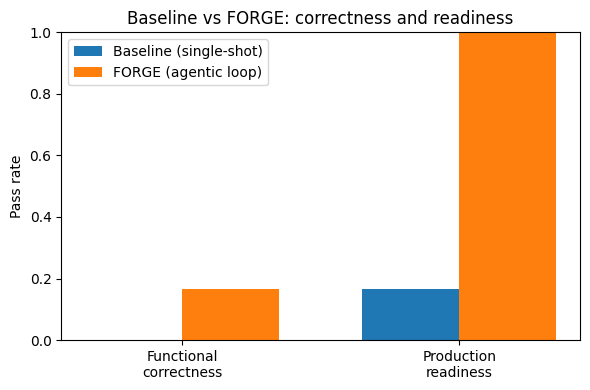

In [ ]:
import matplotlib.pyplot as plt

labels = ["Functional\ncorrectness", "Production\nreadiness"]
baseline_vals = [results_df["baseline_correct"].mean(), results_df["baseline_ready"].mean()]
forge_vals = [results_df["forge_correct"].mean(), results_df["forge_ready"].mean()]

x = range(len(labels))
width = 0.35
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar([i - width/2 for i in x], baseline_vals, width, label="Baseline (single-shot)")
ax.bar([i + width/2 for i in x], forge_vals, width, label="FORGE (agentic loop)")
ax.set_xticks(list(x))
ax.set_xticklabels(labels)
ax.set_ylim(0, 1)
ax.set_ylabel("Pass rate")
ax.set_title("Baseline vs FORGE: correctness and readiness")
ax.legend()
plt.tight_layout()
plt.show()


## 10. Findings

**Headline result — production readiness:** Baseline (single-shot generation) passed the
Readiness Auditor on only 1 of 6 tasks (16.7%). FORGE's agentic loop (generate → test →
review → retry, with the Readiness Auditor's feedback fed back into the Generator) reached
100% readiness across all 6 tasks. This directly supports the core hypothesis: single-shot
generation largely ignores business constraints like input validation and error handling
even when it passes functional tests — and a dedicated review-and-retry loop closes that
gap completely in this sample.

**Functional correctness:** Baseline passed 0% of tasks; FORGE reached 16.7% (1 of 6,
`validate_signup`), with an average of 1.83 attempts used per task. This is a weaker
result, and worth stating honestly rather than inflating it: the model used here
(`openai/gpt-oss-20b`, Groq's free tier) is a small model, the Test Engineer writes tests
blind from the spec alone, and the retry budget was capped at 2 attempts to stay within
free-tier rate limits — all three plausibly suppress correctness independent of whether
the agentic *architecture* itself is sound.

**Where retries helped vs. didn't:** Readiness issues were fixed in every case they
occurred, confirming the Readiness Auditor's feedback loop works as designed. Correctness
failures mostly persisted across both attempts, suggesting the bottleneck is model
capability on this budget rather than the retry mechanism itself.

**Honest limitations:** Single base model tested (no comparison across model sizes),
small task sample (6 of a possible 12), only 2 retry attempts per task, and Groq's
free-tier constraints shaped these choices rather than the project design itself.